<a href="https://colab.research.google.com/github/Yamuna1911/FDP/blob/main/CCRASD40K_Proposal_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CCRASD-40K: Cholangiocarcinoma Risk Assessment & Staging — Analysis Notebook

**Purpose:** exploratory analysis, statistical testing and machine-learning baselines on the CCRASD-40K dataset, structured to feed directly into a research proposal (problem statement → data → methods → preliminary results → limitations → proposed work).

**Dataset:** 40,000 patient records × 50 columns — demographics, lifestyle, family history, comorbidities / known risk factors (PSC, liver fluke, hepatitis, gallstones, cirrhosis), symptoms, liver-function tests, tumour markers (CA19-9, CEA), imaging (bile-duct dilation), and a 5-level target `Disease_Class` (0–4).

> **Note on the target.** The dataset ships without a codebook for `Disease_Class`. Lab values rise monotonically from class 0 to 4 and class 0 shows normal reference ranges, so this notebook treats it as an **ordinal severity scale (0 = no disease / healthy → 4 = most advanced)**. Confirm the exact meaning with the dataset source before writing the proposal.

### Proposed research questions
1. **RQ1** — Which clinical, biochemical and risk-factor variables are associated with disease class?
2. **RQ2** — How accurately can machine-learning models classify disease class, and which model families perform best?
3. **RQ3** — Which *feature groups* (non-invasive vs. lab-based) carry the predictive signal — i.e. can a low-cost screening model work without blood tests?
4. **RQ4** — How robust are models to measurement noise that real-world lab data would contain?

## 1. Setup

In [4]:
import warnings, os, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score,
                             matthews_corrcoef, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)
try:
    from xgboost import XGBClassifier; HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier; HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

SEED = 42
np.random.seed(SEED)
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)

# Plot style: quiet axes, one sequential blue ramp for the ordinal class (0 light -> 4 dark)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True,
                     'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'font.size': 10, 'axes.titleweight': 'bold'})
CLASS_COLORS = ['#9ec5f4', '#6da7ec', '#3987e5', '#1c5cab', '#0d366b']
ACCENT, ACCENT2 = '#2a78d6', '#eb6834'
def savefig(name): plt.tight_layout(); plt.savefig(f'figures/{name}.png', bbox_inches='tight')
print('xgboost:', HAS_XGB, '| lightgbm:', HAS_LGBM)

xgboost: True | lightgbm: True


## 2. Load data

In [11]:
import os
import pandas as pd

PATH = 'CCRASD-40K_Dataset.csv'   # change if the file is elsewhere
if not os.path.exists(PATH):
    PATH = '/content/CCRASD-40K_Dataset.csv'

if not os.path.exists(PATH):
    raise FileNotFoundError(f"Could not find the dataset file at '{PATH}'. Please upload it or update the PATH variable.")

df = pd.read_csv(PATH)
TARGET = 'Disease_Class'
print(df.shape)
df.head()

(40000, 50)


,Patient_ID,Age,Gender,Height_cm,Weight_kg,BMI,Ethnicity,Residence,Occupation,Blood_Group,...,Total_Bilirubin,ALT,AST,ALP,GGT,Albumin,CA19_9,CEA,Bile_Duct_Dilation,Disease_Class
0,CCRASD00001,72,Male,154,100,25.2,White,Urban,Retired,AB-,...,2.53,27,56,108,123,5.07,98.6,9.12,0,1
1,CCRASD00002,50,Male,188,100,27.8,Black,Rural,Business,B+,...,3.44,45,148,220,159,3.79,204.5,16.24,1,3
2,CCRASD00003,39,Male,170,73,19.2,White,Rural,Labor,AB-,...,2.77,87,142,612,282,3.20,338.1,20.20,1,4
3,CCRASD00004,23,Male,170,97,30.0,White,Urban,Farmer,O-,...,1.57,64,95,361,93,3.81,263.7,11.32,1,2
4,CCRASD00005,59,Male,158,102,18.2,White,Urban,Farmer,B-,...,2.66,92,135,382,188,3.78,183.5,17.31,1,3


### Feature groups
Grouping the 48 predictors is central to the proposal: it lets us ask which *kinds* of information a model needs (RQ3).

In [12]:
GROUPS = {
    'Demographics': ['Age','Gender','Height_cm','Weight_kg','BMI','Ethnicity','Residence','Occupation','Blood_Group'],
    'Lifestyle & environment': ['Smoking_Status','Alcohol_Consumption','Physical_Activity','Dietary_Habits','Water_Source'],
    'Family history': ['Family_History_Cancer','Family_History_Liver_Disease','Family_History_Biliary_Disease'],
    'Comorbidities & risk factors': ['Diabetes','Hypertension','Obesity','Chronic_Liver_Disease','Liver_Cirrhosis',
                                     'Hepatitis_B','Hepatitis_C','Primary_Sclerosing_Cholangitis','Gallstones',
                                     'Liver_Fluke_Infection','Inflammatory_Bowel_Disease'],
    'Symptoms': ['Jaundice','Abdominal_Pain','Weight_Loss','Fever','Fatigue','Dark_Urine','Pale_Stool',
                 'Itchy_Skin','Loss_of_Appetite','Nausea','Vomiting'],
    'Liver function tests': ['Total_Bilirubin','ALT','AST','ALP','GGT','Albumin'],
    'Tumour markers': ['CA19_9','CEA'],
    'Imaging': ['Bile_Duct_Dilation'],
}
CATEGORICAL = ['Gender','Ethnicity','Residence','Occupation','Blood_Group']
ORDINAL_3 = ['Physical_Activity','Dietary_Habits','Water_Source']          # coded 0/1/2
CONTINUOUS = ['Age','Height_cm','Weight_kg','BMI'] + GROUPS['Liver function tests'] + GROUPS['Tumour markers']
BINARY = [c for g in GROUPS.values() for c in g if c not in CATEGORICAL + ORDINAL_3 + CONTINUOUS]
ALL_FEATURES = [c for g in GROUPS.values() for c in g]
assert set(ALL_FEATURES) | {'Patient_ID', TARGET} == set(df.columns)
pd.DataFrame({'Group': list(GROUPS), 'n_features': [len(v) for v in GROUPS.values()]})

,Group,n_features
0,Demographics,9
1,Lifestyle & environment,5
2,Family history,3
3,Comorbidities & risk factors,11
4,Symptoms,11
5,Liver function tests,6
6,Tumour markers,2
7,Imaging,1


## 3. Data quality checks

In [13]:
qc = {
    'Rows': len(df),
    'Missing values (total)': int(df.isna().sum().sum()),
    'Duplicate rows': int(df.duplicated().sum()),
    'Duplicate Patient_IDs': int(df['Patient_ID'].duplicated().sum()),
    'Duplicate feature rows (excl. ID)': int(df.drop(columns='Patient_ID').duplicated().sum()),
}
# BMI consistency: does recorded BMI match weight / height^2 ?
bmi_calc = df['Weight_kg'] / (df['Height_cm']/100)**2
qc['BMI |recorded - computed| > 1'] = int((abs(df['BMI'] - bmi_calc) > 1).sum())
# Obesity flag vs BMI >= 30
qc['Obesity flag disagrees with BMI>=30'] = int(((df['BMI'] >= 30).astype(int) != df['Obesity']).sum())
pd.Series(qc, name='value').to_frame()

,value
Rows,40000
Missing values (total),0
Duplicate rows,0
Duplicate Patient_IDs,0
Duplicate feature rows (excl. ID),0
BMI |recorded - computed| > 1,37054
Obesity flag disagrees with BMI>=30,20031


**Interpretation.** No missing values or duplicates. However, check the last two rows: if recorded BMI does not match height/weight, or the `Obesity` flag disagrees with BMI ≥ 30, the anthropometric variables were generated independently. This is a strong sign the dataset is **synthetic** and should be reported as a limitation in the proposal.

In [14]:
desc = df[CONTINUOUS].describe().T
desc['skew'] = df[CONTINUOUS].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
Age,40000.0,52.44,19.06,20.0,36.00,52.00,69.00,85.0,0.01
Height_cm,40000.0,167.52,13.26,145.0,156.00,168.00,179.00,190.0,-0.01
Weight_kg,40000.0,77.42,19.06,45.0,61.00,77.00,94.00,110.0,0.01
BMI,40000.0,28.04,5.76,18.0,23.00,28.00,33.00,38.0,-0.01
Total_Bilirubin,40000.0,3.08,2.28,0.3,1.11,2.60,4.48,10.0,0.93
ALT,40000.0,72.95,43.48,15.0,38.00,63.00,100.00,205.0,0.90
AST,40000.0,68.91,39.01,15.0,38.00,61.00,93.00,185.0,0.85
ALP,40000.0,242.19,135.63,50.0,127.00,221.00,331.00,620.0,0.70
GGT,40000.0,139.99,87.83,20.0,64.00,126.00,198.00,390.0,0.74
Albumin,40000.0,4.48,0.54,2.8,4.16,4.61,4.91,5.2,-0.95


## 4. Exploratory data analysis
### 4.1 Target distribution

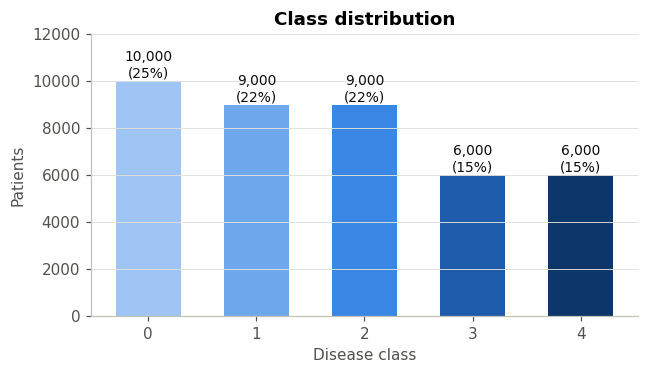

Imbalance ratio (max/min): 1.67


In [15]:
vc = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6,3.5))
bars = ax.bar(vc.index.astype(str), vc.values, color=CLASS_COLORS, width=0.6)
for b, v in zip(bars, vc.values):
    ax.text(b.get_x()+b.get_width()/2, v+150, f'{v:,}\n({v/len(df):.0%})', ha='center', fontsize=9, color='#0b0b0b')
ax.set(xlabel='Disease class', ylabel='Patients', title='Class distribution'); ax.set_ylim(0, vc.max()*1.2)
ax.grid(axis='x', visible=False); savefig('01_class_distribution'); plt.show()
print('Imbalance ratio (max/min):', round(vc.max()/vc.min(), 2))

Mild imbalance (≈1.7:1). We use **stratified** splits and report **macro-F1** and **balanced accuracy**, not just accuracy.

### 4.2 Demographics by class

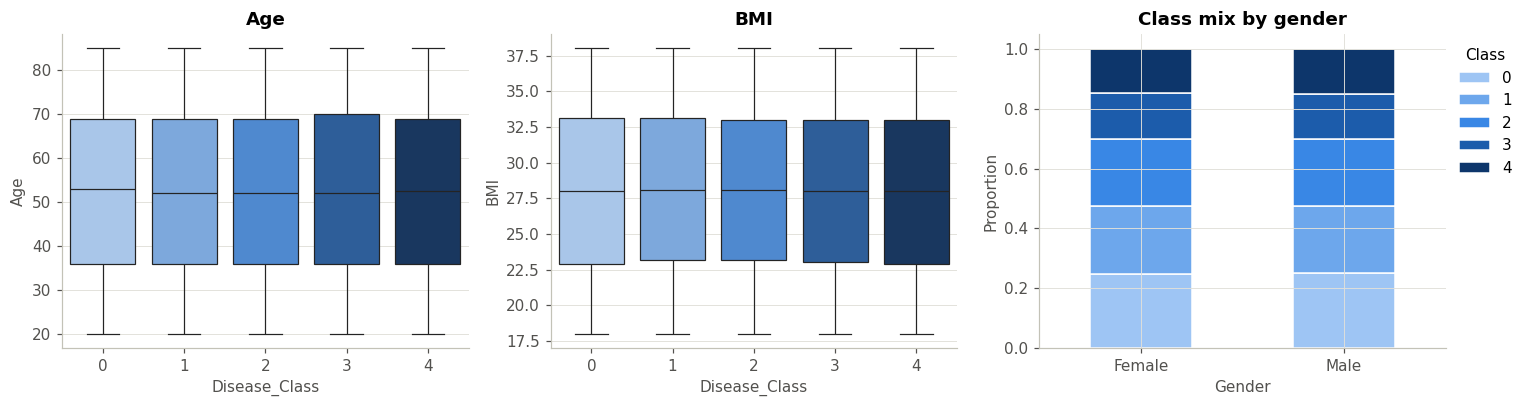

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14,3.8))
sns.boxplot(data=df, x=TARGET, y='Age', palette=CLASS_COLORS, ax=axes[0], fliersize=1, linewidth=0.8)
sns.boxplot(data=df, x=TARGET, y='BMI', palette=CLASS_COLORS, ax=axes[1], fliersize=1, linewidth=0.8)
pd.crosstab(df['Gender'], df[TARGET], normalize='index').plot.bar(stacked=True, color=CLASS_COLORS, ax=axes[2],
                                                                    edgecolor='white', linewidth=1, rot=0)
axes[0].set_title('Age'); axes[1].set_title('BMI'); axes[2].set_title('Class mix by gender')
axes[2].legend(title='Class', bbox_to_anchor=(1,1), frameon=False); axes[2].set_ylabel('Proportion')
savefig('02_demographics'); plt.show()

### 4.3 Prevalence of binary risk factors and symptoms by class

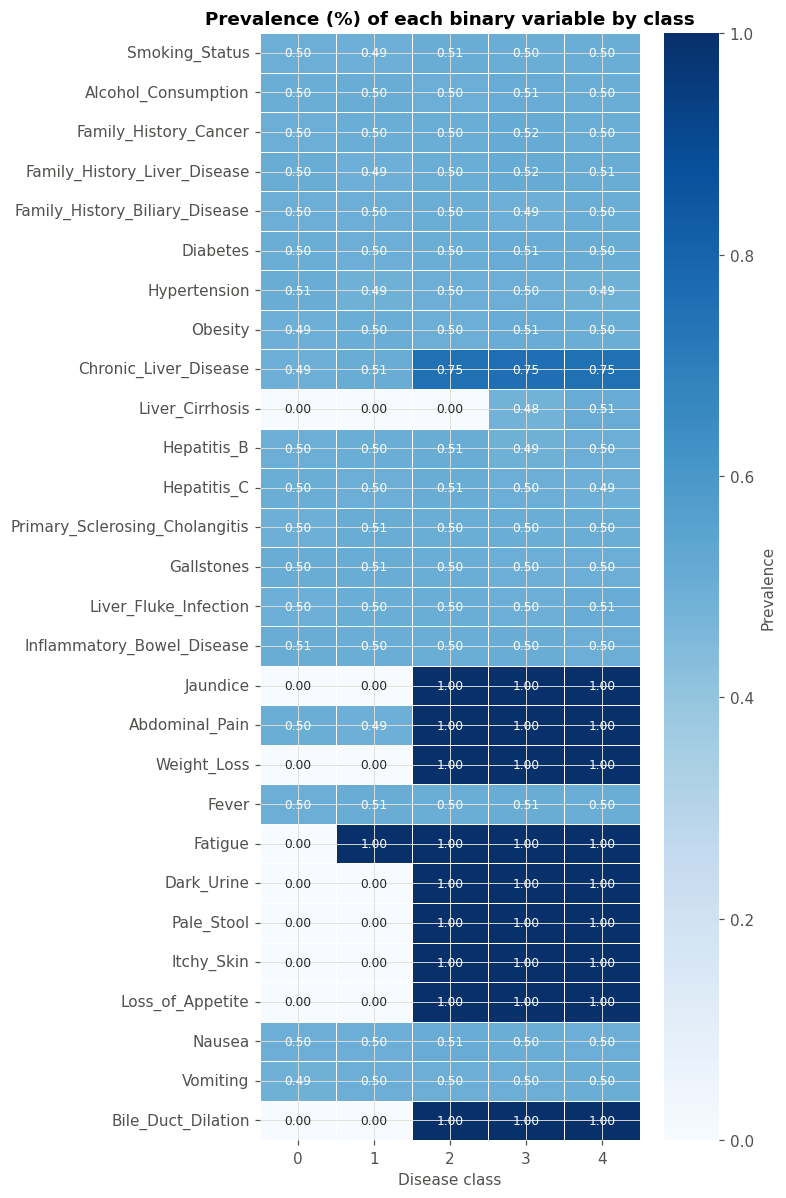

In [17]:
prev = df.groupby(TARGET)[BINARY].mean().T
fig, ax = plt.subplots(figsize=(7, 11))
sns.heatmap(prev, cmap='Blues', annot=True, fmt='.2f', vmin=0, vmax=1, cbar_kws={'label':'Prevalence'},
            linewidths=0.5, linecolor='white', ax=ax, annot_kws={'size':8})
ax.set(title='Prevalence (%) of each binary variable by class', xlabel='Disease class', ylabel='')
savefig('03_binary_prevalence_heatmap'); plt.show()

**What to look for:** rows that jump from exactly 0.00 to 1.00 between classes (e.g. jaundice, dark urine, pale stool between class 1 and 2; cirrhosis appearing only at class 3+). Real clinical data never shows perfect 0/100 % splits — these act as near-deterministic rules and are discussed in §6.

### 4.4 Liver function tests and tumour markers by class

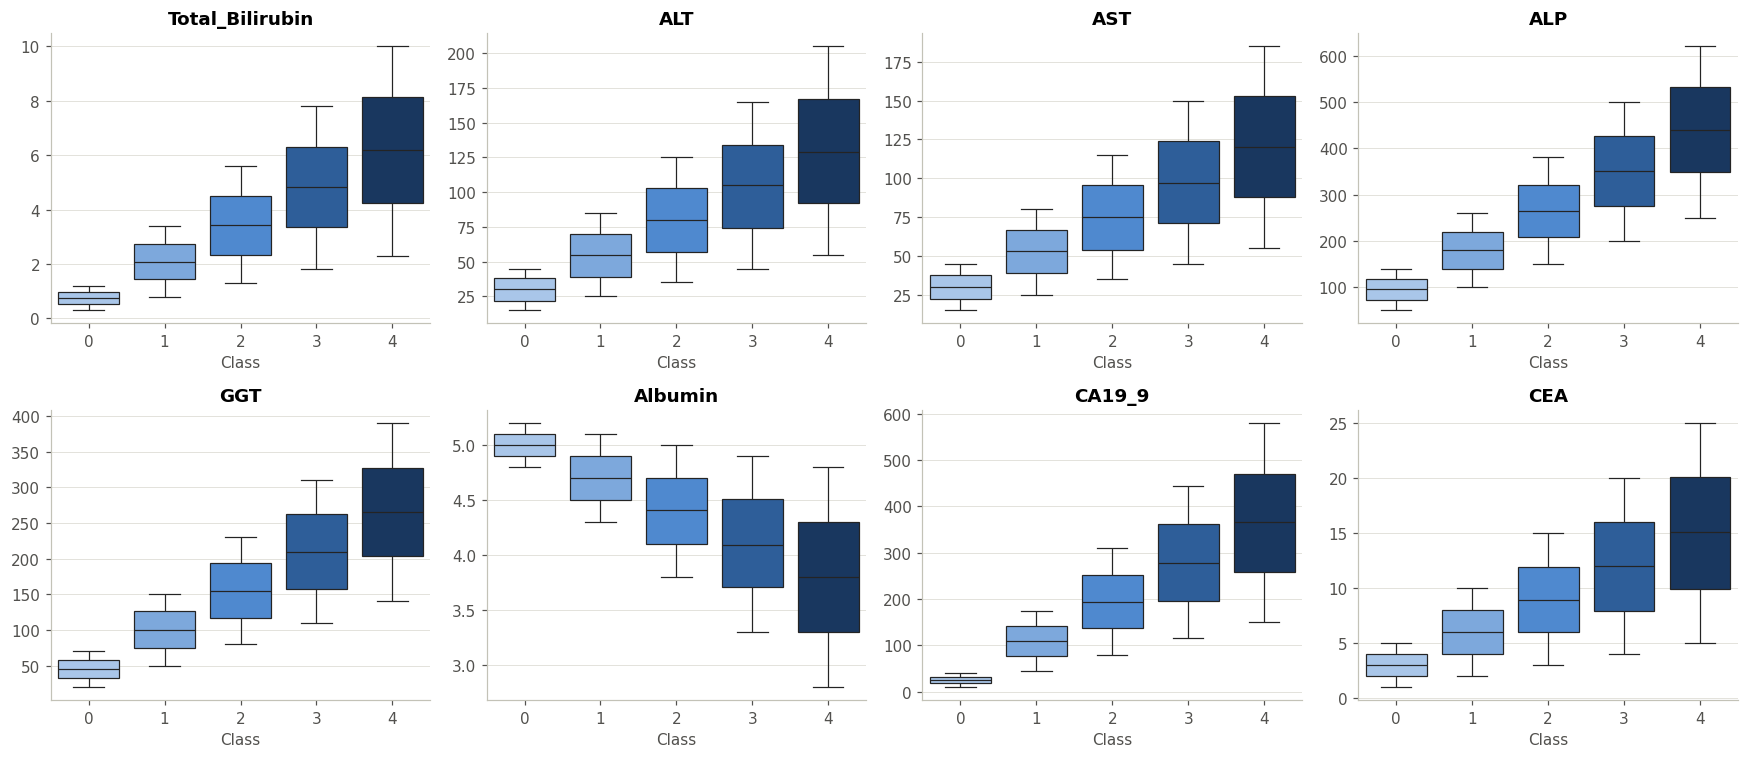

In [19]:
labs = GROUPS['Liver function tests'] + GROUPS['Tumour markers']
fig, axes = plt.subplots(2, 4, figsize=(16,7)); axes = axes.ravel()
for ax, c in zip(axes, labs):
    sns.boxplot(data=df, x=TARGET, y=c, palette=CLASS_COLORS, ax=ax, fliersize=1, linewidth=0.8)
    ax.set_title(c); ax.set_xlabel('Class'); ax.set_ylabel('')
savefig('04_labs_by_class'); plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8,4))
for k, col in zip(sorted(df[TARGET].unique()), CLASS_COLORS):
    sns.kdeplot(df.loc[df[TARGET]==k, 'CA19_9'], ax=ax, color=col, lw=2, label=f'Class {k}')
ax.axvline(37, color='#52514e', ls='--', lw=1); ax.text(40, ax.get_ylim()[1]*0.9, 'Clinical cut-off 37 U/mL', fontsize=8, color='#52514e')
ax.set(title='CA19-9 distribution by class', xlabel='CA19-9 (U/mL)'); ax.legend(frameon=False)
savefig('05_ca199_density'); plt.show()

### 4.5 Correlation structure

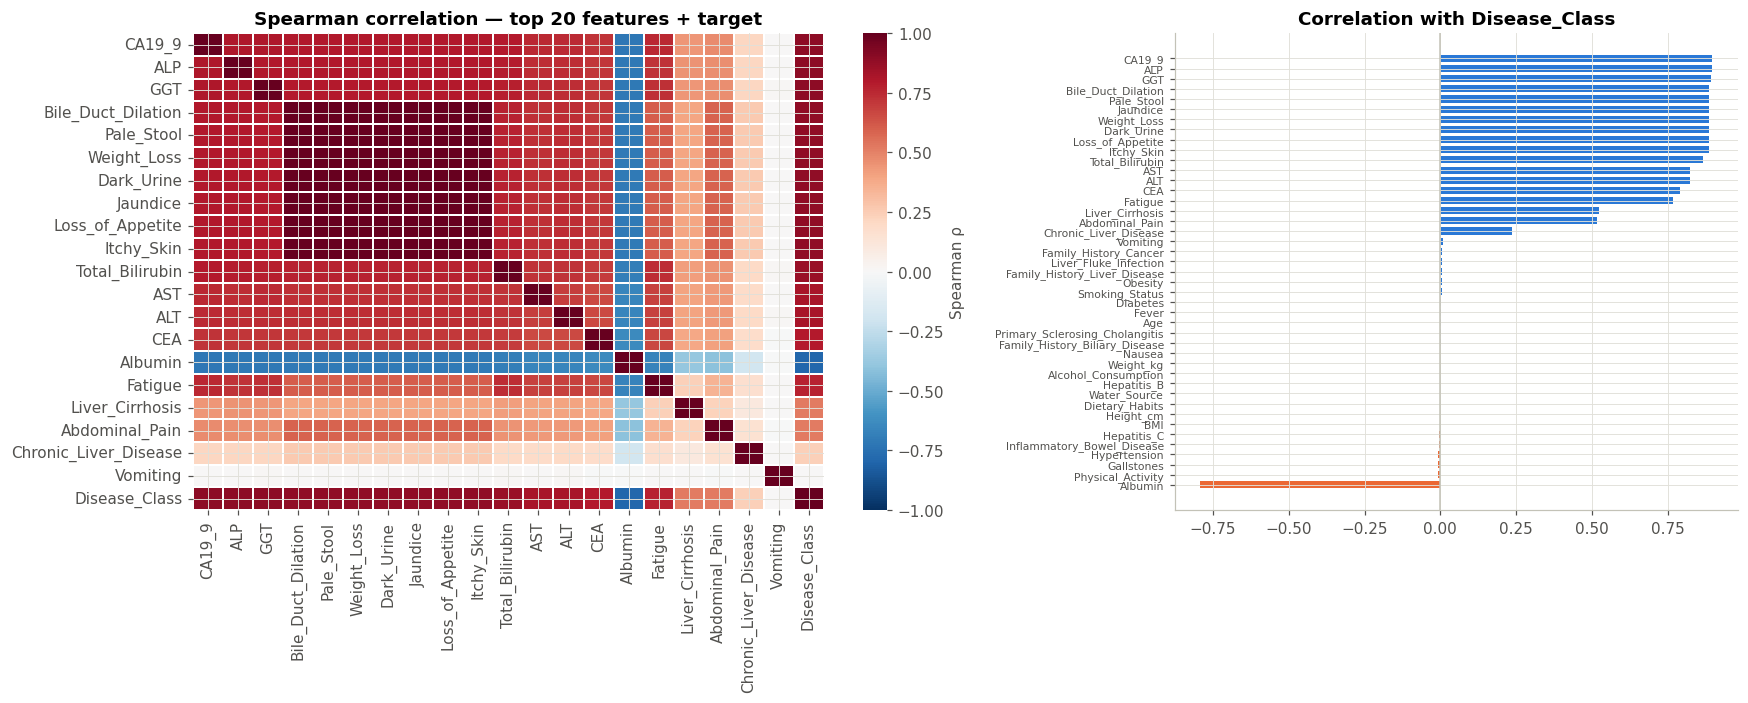

In [18]:
num = df[ALL_FEATURES + [TARGET]].select_dtypes('number')
corr = num.corr(method='spearman')
top = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16,6.5), gridspec_kw={'width_ratios':[1.4,1]})
keep = top.index[:20].tolist() + [TARGET]
sns.heatmap(corr.loc[keep, keep], cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0],
            linewidths=0.3, linecolor='white', cbar_kws={'label':'Spearman ρ'})
axes[0].set_title('Spearman correlation — top 20 features + target')
s = corr[TARGET].drop(TARGET).sort_values()
axes[1].barh(s.index, s.values, color=[ACCENT if v>0 else ACCENT2 for v in s.values], height=0.7)
axes[1].set_title('Correlation with Disease_Class'); axes[1].tick_params(axis='y', labelsize=7)
axes[1].axvline(0, color='#c3c2b7', lw=1)
savefig('06_correlation'); plt.show()

## 5. Statistical association tests (RQ1)
Chi-square (with Cramér's V) for categorical/binary variables; Kruskal–Wallis (with ε²) for continuous/ordinal variables. Bonferroni correction across all tests.

In [20]:
rows = []
n = len(df); k = df[TARGET].nunique()
for c in CATEGORICAL + BINARY + ORDINAL_3:
    ct = pd.crosstab(df[c], df[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    rows.append([c, 'Chi-square', chi2, p, v, "Cramér's V"])
for c in CONTINUOUS:
    H, p = stats.kruskal(*[g[c].values for _, g in df.groupby(TARGET)])
    eps2 = (H - k + 1) / (n - k)
    rows.append([c, 'Kruskal-Wallis', H, p, eps2, 'ε²'])
res = pd.DataFrame(rows, columns=['Variable','Test','Statistic','p_value','Effect_size','Effect_measure'])
res['p_bonferroni'] = np.minimum(res['p_value'] * len(res), 1)
res['Significant (α=0.05)'] = res['p_bonferroni'] < 0.05
grp_of = {c: g for g, cols in GROUPS.items() for c in cols}
res.insert(1, 'Group', res['Variable'].map(grp_of))
res = res.sort_values('Effect_size', ascending=False).reset_index(drop=True)
res.to_csv('results/statistical_tests.csv', index=False)
print(f"{res['Significant (α=0.05)'].sum()} of {len(res)} variables significant after Bonferroni")
res.round(4)

19 of 48 variables significant after Bonferroni


,Variable,Group,Test,Statistic,p_value,Effect_size,Effect_measure,p_bonferroni,Significant (α=0.05)
0,Bile_Duct_Dilation,Imaging,Chi-square,40000.0000,0.0000,1.0000,Cramér's V,0.0,True
1,Fatigue,Symptoms,Chi-square,40000.0000,0.0000,1.0000,Cramér's V,0.0,True
2,Pale_Stool,Symptoms,Chi-square,40000.0000,0.0000,1.0000,Cramér's V,0.0,True
3,Itchy_Skin,Symptoms,Chi-square,40000.0000,0.0000,1.0000,Cramér's V,0.0,True
4,Loss_of_Appetite,Symptoms,Chi-square,40000.0000,0.0000,1.0000,Cramér's V,0.0,True
5,Dark_Urine,Symptoms,Chi-square,40000.0000,0.0000,1.0000,Cramér's V,0.0,True
6,Jaundice,Symptoms,Chi-square,40000.0000,0.0000,1.0000,Cramér's V,0.0,True
7,Weight_Loss,Symptoms,Chi-square,40000.0000,0.0000,1.0000,Cramér's V,0.0,True
8,CA19_9,Tumour markers,Kruskal-Wallis,32665.8651,0.0000,0.8166,ε²,0.0,True
9,ALP,Liver function tests,Kruskal-Wallis,32214.7907,0.0000,0.8054,ε²,0.0,True


In [ ]:
fig, ax = plt.subplots(figsize=(8, 10))
r = res.sort_values('Effect_size')
ax.barh(r['Variable'], r['Effect_size'], color=np.where(r['Significant (α=0.05)'], ACCENT, '#c3c2b7'), height=0.7)
ax.set(title='Effect size of association with disease class', xlabel="Cramér's V  /  ε²")
ax.tick_params(axis='y', labelsize=7)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ACCENT, label='Significant (Bonferroni)'), Patch(color='#c3c2b7', label='Not significant')],
          frameon=False, loc='lower right')
savefig('07_effect_sizes'); plt.show()

## 6. Separability / leakage audit
Before modelling, check how much any *single* feature determines the class. A depth-3 decision tree on one feature at a time, 5-fold CV.

In [21]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
y = df[TARGET].values
single = []
for c in [c for c in ALL_FEATURES if c not in CATEGORICAL]:
    sc = cross_validate(DecisionTreeClassifier(max_depth=3, random_state=SEED), df[[c]], y, cv=skf,
                        scoring='balanced_accuracy')['test_score'].mean()
    single.append((c, grp_of[c], sc))
single = pd.DataFrame(single, columns=['Feature','Group','Balanced_acc_single_feature']).sort_values(
    'Balanced_acc_single_feature', ascending=False).reset_index(drop=True)
single.to_csv('results/single_feature_separability.csv', index=False)
print('Chance level (5 classes) = 0.20')
single.head(15).round(3)

Chance level (5 classes) = 0.20


,Feature,Group,Balanced_acc_single_feature
0,CA19_9,Tumour markers,0.643
1,GGT,Liver function tests,0.593
2,Total_Bilirubin,Liver function tests,0.587
3,ALP,Liver function tests,0.584
4,ALT,Liver function tests,0.535
5,AST,Liver function tests,0.532
6,CEA,Tumour markers,0.519
7,Albumin,Liver function tests,0.514
8,Bile_Duct_Dilation,Imaging,0.400
9,Weight_Loss,Symptoms,0.400


In [26]:
# Value ranges per class for the strongest lab variables — overlapping or nearly disjoint?
pd.concat({c: df.groupby(TARGET)[c].agg(['min','median','max']) for c in ['CA19_9','CEA','Total_Bilirubin','Albumin']}, axis=1).round(2)

CA19_9                 CEA               Total_Bilirubin         \
                 min  median    max  min median    max             min median   
Disease_Class                                                                   
0               10.0   25.20   40.0  1.0   2.98   5.00             0.3   0.74   
1               45.0  109.60  175.0  2.0   6.01  10.00             0.8   2.09   
2               80.0  194.15  310.0  3.0   8.95  15.00             1.3   3.44   
3              115.1  278.45  444.9  4.0  11.96  19.99             1.8   4.82   
4              150.1  366.45  579.9  5.0  15.07  25.00             2.3   6.20   

                    Albumin              
                max     min median  max  
Disease_Class                            
0               1.2     4.8   5.00  5.2  
1               3.4     4.3   4.70  5.1  
2               5.6     3.8   4.41  5.0  
3               7.8     3.3   4.09  4.9  
4              10.0     2.8   3.80  4.8

**Interpretation for the proposal.** Individual lab variables (especially tumour markers) reach very high balanced accuracy *on their own*, and several symptoms switch from 0 % to 100 % prevalence between classes. This means the class label is close to a deterministic function of a few variables. Near-perfect model scores below should therefore be read as *"the generating rules were recovered"*, not as evidence of clinical performance. The feature-group ablation (§9) and noise-robustness test (§10) are designed to give more honest, publishable findings.

## 7. Train / test split and preprocessing

In [22]:
X = df[ALL_FEATURES].copy(); y = df[TARGET].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Train:', X_train.shape, ' Test:', X_test.shape)

def make_preprocessor(cols):
    cat = [c for c in cols if c in CATEGORICAL]
    numc = [c for c in cols if c not in CATEGORICAL]
    return ColumnTransformer([('num', StandardScaler(), numc),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])

Train: (32000, 48)  Test: (8000, 48)


## 8. Baseline model comparison (RQ2)
All models wrapped in a single pipeline (scaling + one-hot) so there is no preprocessing leakage. 5-fold stratified CV on the training set, then a single evaluation on the held-out test set.

In [28]:
def get_models():
    m = {
        'Dummy (majority)': DummyClassifier(strategy='most_frequent'),
        'Logistic Regression': LogisticRegression(max_iter=2000, C=1.0),
        'KNN (k=15)': KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
        'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=SEED),
        'Random Forest': RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
        'MLP': MLPClassifier(hidden_layer_sizes=(64,32), max_iter=300, early_stopping=True, random_state=SEED),
    }
    if HAS_XGB:  m['XGBoost'] = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.9,
                                              colsample_bytree=0.8, eval_metric='mlogloss', random_state=SEED, n_jobs=-1)
    if HAS_LGBM: m['LightGBM'] = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1)
    return m

SCORING = {'accuracy':'accuracy','balanced_acc':'balanced_accuracy','f1_macro':'f1_macro'}
cv_rows, fitted = [], {}
for name, model in get_models().items():
    pipe = Pipeline([('prep', make_preprocessor(ALL_FEATURES)), ('clf', model)])
    t0 = time.time()
    cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=SCORING, n_jobs=1)
    pipe.fit(X_train, y_train); fitted[name] = pipe
    cv_rows.append({'Model': name, **{f'CV_{k}': cv[f'test_{k}'].mean() for k in SCORING},
                    'CV_f1_macro_sd': cv['test_f1_macro'].std(), 'Fit_time_s': time.time()-t0})
    print(f'{name:22s} CV macro-F1 = {cv["test_f1_macro"].mean():.4f} ± {cv["test_f1_macro"].std():.4f}')
cv_df = pd.DataFrame(cv_rows)

Dummy (majority)       CV macro-F1 = 0.0800 ± 0.0000
Logistic Regression    CV macro-F1 = 0.9133 ± 0.0050
KNN (k=15)             CV macro-F1 = 0.8234 ± 0.0042
Decision Tree          CV macro-F1 = 0.9570 ± 0.0012
Random Forest          CV macro-F1 = 0.9834 ± 0.0014
MLP                    CV macro-F1 = 0.9114 ± 0.0034
XGBoost                CV macro-F1 = 0.9828 ± 0.0011
LightGBM               CV macro-F1 = 0.9823 ± 0.0013


In [29]:
def evaluate(model, Xt, yt):
    pred = model.predict(Xt); proba = model.predict_proba(Xt)
    return {'Accuracy': accuracy_score(yt, pred), 'Balanced_acc': balanced_accuracy_score(yt, pred),
            'Macro_F1': f1_score(yt, pred, average='macro'), 'MCC': matthews_corrcoef(yt, pred),
            'QW_Kappa': cohen_kappa_score(yt, pred, weights='quadratic'),   # ordinal-aware
            'ROC_AUC_ovr': roc_auc_score(yt, proba, multi_class='ovr')}
test_df = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in fitted.items()}).T
results = cv_df.set_index('Model').join(test_df).sort_values('Macro_F1', ascending=False)
results.to_csv('results/model_comparison.csv')
results.round(4)

,CV_accuracy,CV_balanced_acc,CV_f1_macro,CV_f1_macro_sd,Fit_time_s,Accuracy,Balanced_acc,Macro_F1,MCC,QW_Kappa,ROC_AUC_ovr
Model,,,,,,,,,,,
Random Forest,0.9872,0.9829,0.9834,0.0014,63.7904,0.9882,0.9843,0.9849,0.9852,0.9969,0.9975
LightGBM,0.9863,0.9818,0.9823,0.0013,71.8424,0.9880,0.9840,0.9846,0.9849,0.9968,0.9987
XGBoost,0.9867,0.9823,0.9828,0.0011,48.8998,0.9875,0.9833,0.9839,0.9843,0.9967,0.9986
Decision Tree,0.9668,0.9557,0.9570,0.0012,1.6777,0.9698,0.9597,0.9609,0.9623,0.9912,0.9921
MLP,0.9307,0.9108,0.9114,0.0034,38.4354,0.9354,0.9164,0.9170,0.9183,0.9828,0.9912
Logistic Regression,0.9319,0.9126,0.9133,0.0050,26.9106,0.9269,0.9060,0.9066,0.9076,0.9806,0.9900
KNN (k=15),0.8639,0.8187,0.8234,0.0042,18.6657,0.8661,0.8215,0.8263,0.8344,0.9502,0.9747
Dummy (majority),0.2500,0.2000,0.0800,0.0000,0.8618,0.2500,0.2000,0.0800,0.0000,0.0000,0.5000


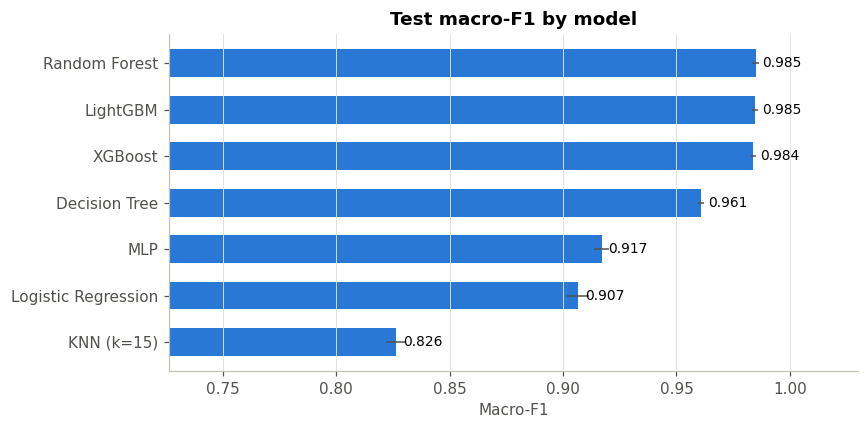

In [25]:
r = results.drop('Dummy (majority)').sort_values('Macro_F1')
fig, ax = plt.subplots(figsize=(8,4))
ax.barh(r.index, r['Macro_F1'], color=ACCENT, height=0.6, xerr=r['CV_f1_macro_sd'], error_kw={'ecolor':'#52514e','lw':1})
for i, v in enumerate(r['Macro_F1']): ax.text(v+0.003, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlim(max(0, r['Macro_F1'].min()-0.1), 1.03); ax.set(title='Test macro-F1 by model', xlabel='Macro-F1')
ax.grid(axis='y', visible=False); savefig('08_model_comparison'); plt.show()

### 8.1 Best model — detailed evaluation

Best model: Random Forest 

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      2000
           1     1.0000    1.0000    1.0000      1800
           2     0.9890    1.0000    0.9945      1800
           3     0.9424    0.9817    0.9616      1200
           4     0.9982    0.9400    0.9682      1200

    accuracy                         0.9882      8000
   macro avg     0.9859    0.9843    0.9849      8000
weighted avg     0.9886    0.9882    0.9882      8000



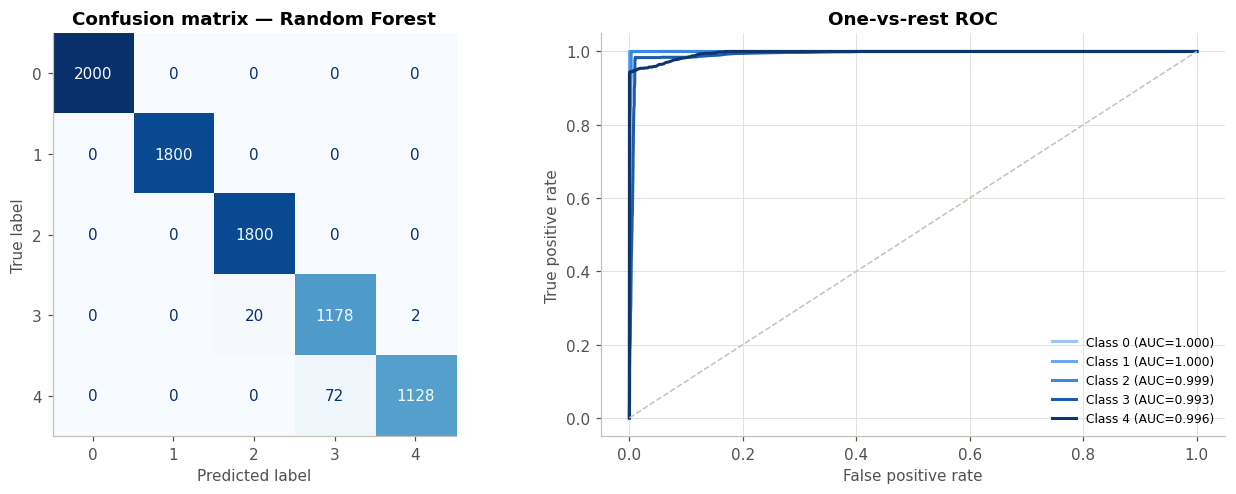

In [27]:
best_name = results.drop('Dummy (majority)').index[0]
best = fitted[best_name]; pred = best.predict(X_test)
print('Best model:', best_name, '\n')
print(classification_report(y_test, pred, digits=4))
fig, axes = plt.subplots(1, 2, figsize=(12,4.6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion matrix — {best_name}'); axes[0].grid(False)
proba = best.predict_proba(X_test)
for k, col in enumerate(CLASS_COLORS):
    fpr, tpr, _ = roc_curve(y_test == k, proba[:, k])
    axes[1].plot(fpr, tpr, color=col, lw=2, label=f'Class {k} (AUC={roc_auc_score(y_test==k, proba[:,k]):.3f})')
axes[1].plot([0,1],[0,1], color='#c3c2b7', ls='--', lw=1)
axes[1].set(title='One-vs-rest ROC', xlabel='False positive rate', ylabel='True positive rate'); axes[1].legend(frameon=False, fontsize=8)
savefig('09_best_model_eval'); plt.show()

### 8.2 Feature importance (permutation, on test set)

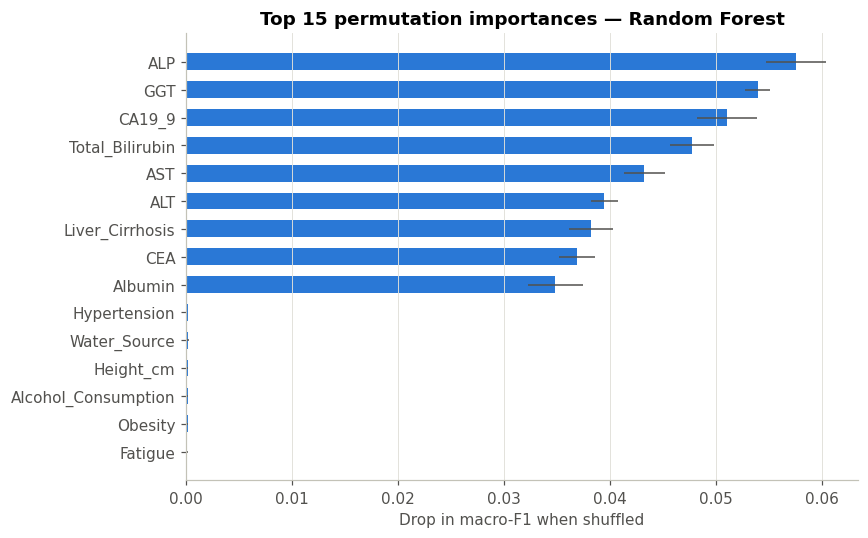

,Feature,Importance,SD,Group
0,ALP,0.0576,0.0028,Liver function tests
1,GGT,0.0539,0.0012,Liver function tests
2,CA19_9,0.0510,0.0028,Tumour markers
3,Total_Bilirubin,0.0477,0.0021,Liver function tests
4,AST,0.0433,0.0019,Liver function tests
5,ALT,0.0395,0.0013,Liver function tests
6,Liver_Cirrhosis,0.0382,0.0021,Comorbidities & risk factors
7,CEA,0.0369,0.0017,Tumour markers
8,Albumin,0.0349,0.0026,Liver function tests
9,Hypertension,0.0002,0.0000,Comorbidities & risk factors


In [31]:
pi = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=SEED, scoring='f1_macro', n_jobs=-1)
imp = pd.DataFrame({'Feature': ALL_FEATURES, 'Importance': pi.importances_mean, 'SD': pi.importances_std})
imp['Group'] = imp['Feature'].map(grp_of)
imp = imp.sort_values('Importance', ascending=False).reset_index(drop=True)
imp.to_csv('results/permutation_importance.csv', index=False)
t = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(t['Feature'], t['Importance'], xerr=t['SD'], color=ACCENT, height=0.6, error_kw={'ecolor':'#52514e','lw':1})
ax.set(title=f'Top 15 permutation importances — {best_name}', xlabel='Drop in macro-F1 when shuffled')
ax.grid(axis='y', visible=False); savefig('10_permutation_importance'); plt.show()
imp.head(15).round(4)

Because many features are redundant (e.g. all lab values rise together), permutation importance can understate any one of them — shuffling one is compensated by the others. The group ablation below answers the question more cleanly.

## 9. Feature-group ablation (RQ3)
Train the same model on each feature group alone, and on clinically meaningful combinations. This is the key result for a *screening-oriented* proposal: what accuracy is achievable **without** blood tests or imaging?

In [32]:
def ablation_model():
    if HAS_LGBM: return LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=SEED, verbose=-1)
    return RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)

NONINVASIVE = GROUPS['Demographics'] + GROUPS['Lifestyle & environment'] + GROUPS['Family history'] + GROUPS['Comorbidities & risk factors']
SETS = {**{f'[G] {g}': cols for g, cols in GROUPS.items()},
        '[C] Risk profile only (demog+lifestyle+family+comorb.)': NONINVASIVE,
        '[C] Risk profile + symptoms (no labs/imaging)': NONINVASIVE + GROUPS['Symptoms'],
        '[C] All except tumour markers': [c for c in ALL_FEATURES if c not in GROUPS['Tumour markers']],
        '[C] All except labs & markers': [c for c in ALL_FEATURES if c not in labs],
        '[C] All features': ALL_FEATURES}
abl = []
for name, cols in SETS.items():
    pipe = Pipeline([('prep', make_preprocessor(cols)), ('clf', ablation_model())]).fit(X_train[cols], y_train)
    m = evaluate(pipe, X_test[cols], y_test); abl.append({'Feature set': name, 'n_features': len(cols), **m})
abl = pd.DataFrame(abl).sort_values('Macro_F1', ascending=False).reset_index(drop=True)
abl.to_csv('results/feature_group_ablation.csv', index=False)
abl.round(4)

,Feature set,n_features,Accuracy,Balanced_acc,Macro_F1,MCC,QW_Kappa,ROC_AUC_ovr
0,[C] All features,48,0.9880,0.9840,0.9846,0.9849,0.9968,0.9987
1,[C] All except tumour markers,46,0.9769,0.9692,0.9702,0.9710,0.9935,0.9970
2,[G] Liver function tests,6,0.9649,0.9554,0.9579,0.9558,0.9900,0.9959
3,[G] Tumour markers,2,0.8002,0.7606,0.7663,0.7502,0.9062,0.9485
4,[C] Risk profile + symptoms (no labs/imaging),39,0.7700,0.6940,0.6748,0.7215,0.8643,0.9176
5,[C] All except labs & markers,40,0.7700,0.6940,0.6748,0.7215,0.8643,0.9176
6,[G] Symptoms,11,0.7000,0.6000,0.5200,0.6740,0.7323,0.8749
7,[C] Risk profile only (demog+lifestyle+family+...,28,0.3584,0.3419,0.3359,0.1857,0.4799,0.6922
8,[G] Comorbidities & risk factors,11,0.3444,0.3291,0.3228,0.1669,0.4707,0.6936
9,[G] Imaging,1,0.4750,0.4000,0.2579,0.3791,0.7092,0.8108


In [ ]:
a = abl.sort_values('Macro_F1')
fig, ax = plt.subplots(figsize=(9,5.5))
ax.barh(a['Feature set'], a['Macro_F1'], color=[ACCENT if s.startswith('[C]') else '#86b6ef' for s in a['Feature set']], height=0.65)
ax.axvline(0.2, color='#52514e', ls='--', lw=1); ax.text(0.205, -0.6, 'chance ≈ 0.20', fontsize=8, color='#52514e')
for i, v in enumerate(a['Macro_F1']): ax.text(v+0.01, i, f'{v:.3f}', va='center', fontsize=8)
ax.set(xlim=(0,1.08), title='Macro-F1 by feature set ([G] single group, [C] combination)', xlabel='Test macro-F1')
ax.grid(axis='y', visible=False); savefig('11_feature_group_ablation'); plt.show()

## 10. Robustness to measurement noise (RQ4)
Real lab measurements carry analytical and biological variation. We add multiplicative Gaussian noise (coefficient of variation, CV%) to the continuous lab variables in the **test set only** and track performance of models trained on clean data.

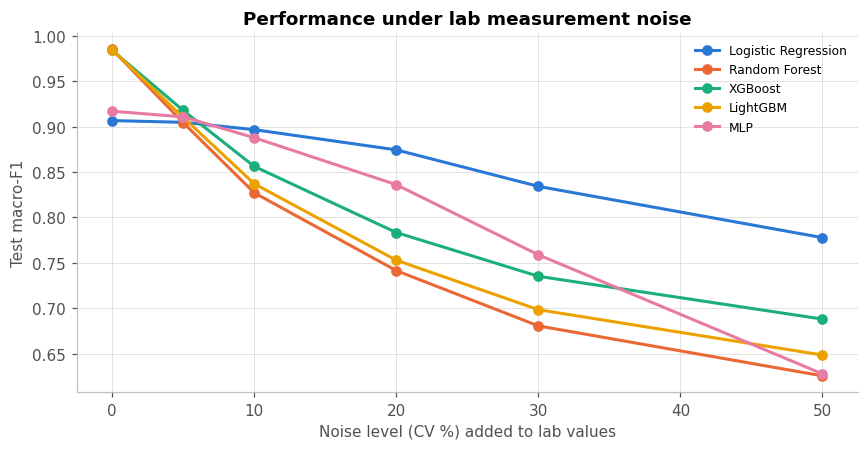

Model,LightGBM,Logistic Regression,MLP,Random Forest,XGBoost
Noise_CV,,,,,
0.00,0.9846,0.9066,0.9170,0.9849,0.9839
0.05,0.9102,0.9047,0.9107,0.9043,0.9177
0.10,0.8370,0.8966,0.8878,0.8271,0.8562
0.20,0.7529,0.8744,0.8360,0.7415,0.7834
0.30,0.6985,0.8342,0.7589,0.6806,0.7352
0.50,0.6485,0.7778,0.6278,0.6256,0.6881


In [33]:
rng = np.random.default_rng(SEED)
noise_levels = [0, 0.05, 0.10, 0.20, 0.30, 0.50]
robust_models = {k: fitted[k] for k in ['Logistic Regression','Random Forest','XGBoost','LightGBM','MLP'] if k in fitted}
rob = []
for cvn in noise_levels:
    Xn = X_test.copy()
    for c in labs:
        Xn[c] = np.clip(Xn[c] * (1 + rng.normal(0, cvn, len(Xn))), 0, None)
    for n, m in robust_models.items():
        rob.append({'Noise_CV': cvn, 'Model': n, 'Macro_F1': f1_score(y_test, m.predict(Xn), average='macro')})
rob = pd.DataFrame(rob); rob.to_csv('results/noise_robustness.csv', index=False)
pal = ['#2a78d6','#eb6834','#1baf7a','#eda100','#e87ba4']
fig, ax = plt.subplots(figsize=(8,4.2))
for (n, g), col in zip(rob.groupby('Model', sort=False), pal):
    ax.plot(g['Noise_CV']*100, g['Macro_F1'], marker='o', ms=6, lw=2, color=col, label=n)
ax.set(title='Performance under lab measurement noise', xlabel='Noise level (CV %) added to lab values', ylabel='Test macro-F1')
ax.legend(frameon=False, fontsize=8); savefig('12_noise_robustness'); plt.show()
rob.pivot(index='Noise_CV', columns='Model', values='Macro_F1').round(4)

## 11. Clinically framed sub-tasks
### 11.1 Binary screening: no disease (class 0) vs any disease (1–4)

In [34]:
yb_tr, yb_te = (y_train > 0).astype(int), (y_test > 0).astype(int)
bin_rows = []
for name, cols in [('Risk profile only', NONINVASIVE), ('Risk profile + symptoms', NONINVASIVE + GROUPS['Symptoms']),
                   ('All features', ALL_FEATURES)]:
    p = Pipeline([('prep', make_preprocessor(cols)), ('clf', ablation_model())]).fit(X_train[cols], yb_tr)
    pr = p.predict_proba(X_test[cols])[:,1]; pd_ = (pr >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb_te, pd_).ravel()
    bin_rows.append({'Feature set': name, 'ROC_AUC': roc_auc_score(yb_te, pr), 'Sensitivity': tp/(tp+fn),
                     'Specificity': tn/(tn+fp), 'PPV': tp/(tp+fp) if tp+fp else np.nan, 'NPV': tn/(tn+fn) if tn+fn else np.nan})
bin_df = pd.DataFrame(bin_rows); bin_df.to_csv('results/binary_screening.csv', index=False); bin_df.round(4)

,Feature set,ROC_AUC,Sensitivity,Specificity,PPV,NPV
0,Risk profile only,0.6738,0.9942,0.009,0.7506,0.3396
1,Risk profile + symptoms,1.0000,1.0000,1.000,1.0000,1.0000
2,All features,1.0000,1.0000,1.000,1.0000,1.0000


### 11.2 Ordinal error analysis
For an ordinal target, predicting class 3 when the truth is 4 is less harmful than predicting 0. Mean absolute class error and the share of predictions off by ≥ 2 classes summarise this.

In [35]:
ord_rows = []
for n, m in fitted.items():
    p = m.predict(X_test); err = np.abs(p - y_test)
    ord_rows.append({'Model': n, 'MAE (classes)': err.mean(), 'Exact': (err==0).mean(), 'Off by 1': (err==1).mean(), 'Off by ≥2': (err>=2).mean()})
pd.DataFrame(ord_rows).sort_values('MAE (classes)').round(4)

,Model,MAE (classes),Exact,Off by 1,Off by ≥2
4,Random Forest,0.0118,0.9882,0.0118,0.0000
7,LightGBM,0.0120,0.9880,0.0120,0.0000
6,XGBoost,0.0125,0.9875,0.0125,0.0000
3,Decision Tree,0.0310,0.9698,0.0295,0.0008
5,MLP,0.0649,0.9354,0.0644,0.0002
1,Logistic Regression,0.0732,0.9269,0.0730,0.0001
2,KNN (k=15),0.1471,0.8661,0.1206,0.0132
0,Dummy (majority),1.7250,0.2500,0.2250,0.5250


## 12. Summary of preliminary results

In [36]:
print('=== Dataset ===')
print(f'{len(df):,} patients, {len(ALL_FEATURES)} predictors, 5 classes; no missing values.')
print(f"{res['Significant (α=0.05)'].sum()}/{len(res)} variables significantly associated with class (Bonferroni).")
print('Strongest associations:', ', '.join(res['Variable'].head(6)))
print('Variables with no association:', ', '.join(res.loc[~res['Significant (α=0.05)'], 'Variable'].head(12)), '...')
print('\n=== Modelling ===')
print(f'Best model: {best_name}  | test macro-F1 = {results.loc[best_name, "Macro_F1"]:.4f}, QW-kappa = {results.loc[best_name, "QW_Kappa"]:.4f}')
print('\n=== Ablation (macro-F1) ===')
print(abl[['Feature set','Macro_F1']].to_string(index=False, float_format='%.3f'))

=== Dataset ===
40,000 patients, 48 predictors, 5 classes; no missing values.
19/48 variables significantly associated with class (Bonferroni).
Strongest associations: Bile_Duct_Dilation, Fatigue, Pale_Stool, Itchy_Skin, Loss_of_Appetite, Dark_Urine
Variables with no association: Blood_Group, Physical_Activity, Family_History_Liver_Disease, Family_History_Cancer, Hypertension, Smoking_Status, Ethnicity, Hepatitis_B, Obesity, Occupation, Hepatitis_C, Vomiting ...

=== Modelling ===
Best model: Random Forest  | test macro-F1 = 0.9849, QW-kappa = 0.9969

=== Ablation (macro-F1) ===
                                           Feature set  Macro_F1
                                      [C] All features     0.985
                         [C] All except tumour markers     0.970
                              [G] Liver function tests     0.958
                                    [G] Tumour markers     0.766
         [C] Risk profile + symptoms (no labs/imaging)     0.675
                        

## 13. Interpretation, limitations and proposed next steps

Numbers below are from the executed run (seed 42, 80/20 stratified split).

**Key findings (preliminary)**
- Disease class is associated mainly with liver-function tests, tumour markers (CA19-9, CEA), cholestatic symptoms, bile-duct dilation, chronic liver disease and cirrhosis. Demographic, lifestyle and most classical risk factors (PSC, liver fluke, hepatitis B/C, gallstones) show **no measurable association** — contrary to the clinical literature on cholangiocarcinoma.
- Tree ensembles (Random Forest, LightGBM, XGBoost) reach **macro-F1 ≈ 0.985** and quadratic-weighted kappa ≈ 0.997 on the full feature set; no prediction is off by more than one class. Logistic regression reaches ≈ 0.91.
- The six **liver-function tests alone give macro-F1 ≈ 0.96**; tumour markers alone ≈ 0.77; symptoms + risk profile (no blood tests) ≈ 0.68.
- For **binary screening (healthy vs. any disease)**, symptoms alone separate the groups perfectly (AUC = 1.00) because `Fatigue` is 0 in every class-0 patient and 1 in every other — a built-in rule, not a clinical finding.
- Under realistic lab noise, tree ensembles drop sharply (≈ 0.98 → 0.83 at 10 % CV) while **logistic regression is the most robust** (≈ 0.90 at 10 % CV, 0.83 at 30 %), suggesting tree models are memorising hard class thresholds.
- Models built on the **risk profile only** reach macro-F1 ≈ 0.34 (chance ≈ 0.20), driven almost entirely by chronic liver disease / cirrhosis — the dataset, as constructed, cannot support a "pre-symptomatic risk prediction" claim.

**Limitations to state in the proposal**
1. **Likely synthetic data:** uniform ~50 % prevalence of most binary features, deterministic 0 %/100 % symptom splits, class-specific non-overlapping lab ranges, and BMI/obesity inconsistencies (§3, §6).
2. **Target leakage risk:** the label appears to be generated from lab thresholds, so high accuracy reflects rule recovery rather than clinical generalisability.
3. **No codebook** for `Disease_Class` and for the 0/1/2 coded lifestyle variables.
4. No external validation cohort; no temporal or site information.

**Proposed methodology for the full study**
1. Confirm label definitions and data provenance with the dataset authors.
2. Treat the task as **ordinal** (e.g. ordinal logistic regression, CORAL/cumulative-link neural nets) and report QW-kappa and MAE alongside macro-F1.
3. Build **two models**: (a) a non-invasive risk-screening model and (b) a lab-based staging model — evaluated separately.
4. Use **nested cross-validation** with hyper-parameter tuning (e.g. Optuna) and report 95 % bootstrap confidence intervals.
5. Add **explainability** (SHAP) and **calibration** analysis (reliability curves, Brier score).
6. Stress-test with realistic lab noise (§10) and validate on an **independent real-world cohort** (e.g. hospital EHR data) before any clinical claim.

**Outputs saved:** `figures/` (12 PNGs at 300 dpi) and `results/` (CSV tables) for direct use in the proposal.